# Binary_EfficientNetB3_Baseline_V2 — Controlled Performance Experiments

Binary classification of dermoscopic skin-lesion images from the already merged, already split,
already deduplicated HAM10000 + ISIC Extra outputs. Labels are **0 = Benign** and
**1 = Malignant**.

This notebook intentionally contains only the two requested experiments after reproducing the
existing checkpoint: **(1) validation-only threshold re-optimization** and **(2) one
fine-tuning pace-fix retrain**. The test set is not read or evaluated until the final cell, after
the model and threshold decision are locked.

## 1. Imports and reproducibility

In [10]:
import json
import logging
import math
import random
import warnings
from datetime import datetime
from pathlib import Path

from IPython.display import display
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M%S')

logger = logging.getLogger('Binary_EfficientNetB3_Baseline_V2_Experiments')
logger.setLevel(logging.INFO)
logger.handlers.clear()
handler = logging.StreamHandler()
handler.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
logger.addHandler(handler)

## 2. Configuration and unchanged project paths

The paths below are the same paths used by the original notebook. The original split files are
loaded without re-splitting, and the test split is retained only for the final evaluation cell.

In [11]:
def find_project_root(start: Path, markers=('Data', 'notebooks')) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(
        f'Could not find a project root containing {markers} above {start}. '
        'Run this notebook from the project root or its notebooks directory.'
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / 'Data' / 'datasets' / 'HAM10000_ISICExtra_binary'
METADATA_DIR = DATASET_DIR / 'metadata'
IMAGES_DIR = DATASET_DIR / 'images'

OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'binary' / 'Binary_EfficientNetB3_Baseline_V2'
CHECKPOINTS_DIR = OUTPUT_DIR / 'checkpoints'
PREDICTIONS_DIR = OUTPUT_DIR / 'predictions'
PLOTS_DIR = OUTPUT_DIR / 'plots'
TRAINING_CURVES_DIR = PLOTS_DIR / 'training_curves'
ROC_PR_DIR = PLOTS_DIR / 'roc_pr_curves'
CONFUSION_MATRICES_DIR = PLOTS_DIR / 'confusion_matrices'
CALIBRATION_DIR = PLOTS_DIR / 'calibration'

for directory in [
    OUTPUT_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR, PLOTS_DIR,
    TRAINING_CURVES_DIR, ROC_PR_DIR, CONFUSION_MATRICES_DIR, CALIBRATION_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'batch_size': 32,
    'num_workers': 0,
    'epochs': 20,
    'early_stopping_patience': 5,
    'grad_clip_norm': 1.0,
    'use_amp': torch.cuda.is_available(),
    'cb_beta': 0.9999,
    'focal_gamma': 2.0,
    'use_tta': True,
    'img_size': 300,
    'backbone_lr': 1e-4,
    'head_lr': 1e-3,
    'weight_decay': 1e-4,
    'warmup_freeze_epochs': 2,
}

logger.info('PROJECT_ROOT: %s', PROJECT_ROOT)
logger.info('DATASET_DIR: %s', DATASET_DIR)
logger.info('OUTPUT_DIR: %s', OUTPUT_DIR)
logger.info('DEVICE: %s', DEVICE)

2026-08-22 11:37:01,150 | INFO | PROJECT_ROOT: D:\SkinCancer_Project
2026-08-22 11:37:01,150 | INFO | DATASET_DIR: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary
2026-08-22 11:37:01,150 | INFO | OUTPUT_DIR: D:\SkinCancer_Project\outputs\binary\Binary_EfficientNetB3_Baseline_V2
2026-08-22 11:37:01,150 | INFO | DEVICE: cuda


## 3. Dataset validation and immutable split loading

In [12]:
BINARY_LABEL_MAP = {'mel': 1, 'bcc': 1, 'akiec': 1, 'nv': 0, 'bkl': 0, 'df': 0, 'vasc': 0}
BINARY_LABEL_NAMES = {0: 'Benign', 1: 'Malignant'}

def verify_dataset(metadata_dir: Path, images_dir: Path) -> None:
    required_files = ['train.csv', 'val.csv', 'test.csv']
    required_columns = {'image_id', 'image_path'}
    missing = [name for name in required_files if not (metadata_dir / name).exists()]
    if missing:
        raise FileNotFoundError(f'Missing expected metadata file(s): {missing}')
    missing_dirs = [name for name in ['train', 'val', 'test'] if not (images_dir / name).exists()]
    if missing_dirs:
        raise FileNotFoundError(f'Missing expected image split folder(s): {missing_dirs}')
    for filename in required_files:
        columns = set(pd.read_csv(metadata_dir / filename, nrows=1).columns)
        missing_columns = required_columns - columns
        if missing_columns:
            raise ValueError(f'{filename} is missing required column(s): {missing_columns}')

def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    result = df.copy()
    split_dir = images_dir / split_name

    def resolve(raw_path: str) -> str:
        current_path = Path(str(raw_path))
        if current_path.parent == split_dir:
            return str(current_path)
        return str(split_dir / current_path.name)

    result['image_path'] = result['image_path'].map(resolve)
    return result

def prepare_binary_labels(df: pd.DataFrame, name: str) -> pd.DataFrame:
    result = df.copy()
    if 'binary_label' not in result.columns:
        if 'dx' not in result.columns:
            raise ValueError(f'{name}: neither binary_label nor dx is available.')
        result['binary_label'] = result['dx'].map(BINARY_LABEL_MAP)
    if result['binary_label'].isna().any():
        raise ValueError(f'{name}: missing or unmapped binary labels found.')
    result['binary_label'] = result['binary_label'].astype(int)
    if set(result['binary_label'].unique()) != {0, 1}:
        raise ValueError(f'{name}: expected exactly labels {{0, 1}}.')
    return result

verify_dataset(METADATA_DIR, IMAGES_DIR)
train_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'train.csv'), IMAGES_DIR, 'train'), 'train'
)
val_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'val.csv'), IMAGES_DIR, 'val'), 'val'
)
test_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'test.csv'), IMAGES_DIR, 'test'), 'test'
)

id_sets = {
    'train': set(train_df['image_id']),
    'val': set(val_df['image_id']),
    'test': set(test_df['image_id']),
}
overlaps = {
    'train_val': id_sets['train'] & id_sets['val'],
    'train_test': id_sets['train'] & id_sets['test'],
    'val_test': id_sets['val'] & id_sets['test'],
}
if sum(len(ids) for ids in overlaps.values()) > 0:
    raise RuntimeError({name: len(ids) for name, ids in overlaps.items()})
if test_df['image_id'].duplicated().any():
    raise RuntimeError('test.csv contains duplicate image_id values.')
logger.info(
    'Splits loaded: train=%d, val=%d, test=%d; test remains untouched until the final cell.',
    len(train_df), len(val_df), len(test_df)
)

2026-08-22 11:37:01,281 | INFO | Splits loaded: train=8587, val=2147, test=2147; test remains untouched until the final cell.


## 4. EfficientNet-B3 model, transforms, and data loaders

These are unchanged from the original notebook: ImageNet1K_V1 preprocessing, 320px resize to a
300px crop, the same training augmentation, and the same three-view TTA (identity, horizontal
flip, vertical flip).

In [13]:
class SkinLesionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row['image_path']) as image:
            image = image.convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        return image, label, row['image_id']

class EfficientNetB3BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = torchvision.models.EfficientNet_B3_Weights.IMAGENET1K_V1
        self.backbone = torchvision.models.efficientnet_b3(weights=self.weights)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_features, 1))
        self.freeze_backbone()

    def forward(self, x):
        return self.backbone(x).squeeze(1)

    def freeze_backbone(self):
        for name, parameter in self.backbone.named_parameters():
            if 'classifier' not in name:
                parameter.requires_grad = False

    def unfreeze_backbone(self):
        for name, parameter in self.backbone.named_parameters():
            if 'classifier' not in name:
                parameter.requires_grad = True

    def backbone_trainable_parameters(self):
        return [
            parameter for name, parameter in self.backbone.named_parameters()
            if 'classifier' not in name and parameter.requires_grad
        ]

    def head_parameters(self):
        return list(self.backbone.classifier.parameters())

preprocessing_model = EfficientNetB3BinaryClassifier()
transform_meta = preprocessing_model.weights.transforms()
CONFIG['resize_size'] = transform_meta.resize_size[0]
CONFIG['img_size'] = transform_meta.crop_size[0]
CONFIG['norm_mean'] = list(transform_meta.mean)
CONFIG['norm_std'] = list(transform_meta.std)
CONFIG['interpolation'] = 'bicubic'
del preprocessing_model

interpolation = InterpolationMode.BICUBIC
train_transform = transforms.Compose([
    transforms.Resize(CONFIG['resize_size'], interpolation=interpolation),
    transforms.RandomCrop(CONFIG['img_size']),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG['norm_mean'], std=CONFIG['norm_std']),
])

def build_eval_transform(hflip=False, vflip=False):
    ops = []
    if hflip:
        ops.append(transforms.RandomHorizontalFlip(p=1.0))
    if vflip:
        ops.append(transforms.RandomVerticalFlip(p=1.0))
    ops.extend([
        transforms.Resize(CONFIG['resize_size'], interpolation=interpolation),
        transforms.CenterCrop(CONFIG['img_size']),
        transforms.ToTensor(),
        transforms.Normalize(mean=CONFIG['norm_mean'], std=CONFIG['norm_std']),
    ])
    return transforms.Compose(ops)

eval_transform = build_eval_transform()
tta_transforms = [
    eval_transform,
    build_eval_transform(hflip=True),
    build_eval_transform(vflip=True),
]

train_dataset = SkinLesionDataset(train_df, train_transform)
val_dataset = SkinLesionDataset(val_df, eval_transform)
test_dataset = SkinLesionDataset(test_df, eval_transform)
train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'], shuffle=True,
    num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)

## 5. Unchanged loss and inference utilities

In [14]:
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta=0.9999, gamma=2.0, device='cpu'):
        super().__init__()
        samples_per_class = np.asarray(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)
        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
        self.gamma = gamma

    def forward(self, logits, targets):
        alpha_t = targets * self.class_weights[1] + (1.0 - targets) * self.class_weights[0]
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probabilities = torch.sigmoid(logits)
        p_t = probabilities * targets + (1.0 - probabilities) * (1.0 - targets)
        return (alpha_t * (1.0 - p_t).pow(self.gamma) * bce_loss).mean()

@torch.no_grad()
def collect_probs_tta(model, df, transform_list):
    model.eval()
    view_probabilities = []
    labels_reference = None
    ids_reference = None
    for transform in transform_list:
        dataset = SkinLesionDataset(df, transform)
        loader = DataLoader(
            dataset, batch_size=CONFIG['batch_size'], shuffle=False,
            num_workers=CONFIG['num_workers'], pin_memory=True
        )
        probabilities, labels, ids = [], [], []
        for images, batch_labels, batch_ids in tqdm(loader, desc='TTA view', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with autocast(enabled=CONFIG['use_amp']):
                logits = model(images)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(batch_ids)
        view_probabilities.append(np.concatenate(probabilities))
        if labels_reference is None:
            labels_reference = np.concatenate(labels).astype(int)
            ids_reference = ids
    return np.mean(view_probabilities, axis=0), labels_reference, ids_reference

@torch.no_grad()
def collect_probs_single(model, loader):
    model.eval()
    probabilities, labels, ids = [], [], []
    with torch.no_grad():
        for images, batch_labels, batch_ids in tqdm(loader, desc='inference', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with autocast(enabled=CONFIG['use_amp']):
                logits = model(images)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(batch_ids)
    return np.concatenate(probabilities), np.concatenate(labels).astype(int), ids

def fit_platt_calibrator(raw_probabilities, labels):
    calibrator = LogisticRegression(C=1e10, solver='lbfgs')
    calibrator.fit(raw_probabilities.reshape(-1, 1), labels.astype(int))
    return calibrator

def calibrated_probabilities(calibrator, raw_probabilities):
    return calibrator.predict_proba(raw_probabilities.reshape(-1, 1))[:, 1]

## 6. Baseline checkpoint reproduction (validation only)

The existing `best_model.pth` is loaded as the baseline. This cell performs inference on the
validation split only, with the original TTA and Platt calibration procedure. The checkpoint's
stored threshold is used for the baseline row; no threshold is selected using test data.

In [15]:
def load_checkpoint(path: Path):
    if not path.exists():
        raise FileNotFoundError(
            f'Original checkpoint not found at {path}. The notebook must be run in the same project '
            'where the original outputs were created.'
        )
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')

original_checkpoint_path = CHECKPOINTS_DIR / 'best_model.pth'
original_checkpoint = load_checkpoint(original_checkpoint_path)
baseline_model = EfficientNetB3BinaryClassifier().to(DEVICE)
baseline_model.load_state_dict(original_checkpoint['model_state'])
baseline_model.eval()

if CONFIG['use_tta']:
    baseline_val_raw, val_labels, val_ids = collect_probs_tta(baseline_model, val_df, tta_transforms)
else:
    baseline_val_raw, val_labels, val_ids = collect_probs_single(baseline_model, val_loader)
baseline_calibrator = fit_platt_calibrator(baseline_val_raw, val_labels)
baseline_val_probs = calibrated_probabilities(baseline_calibrator, baseline_val_raw)

baseline_threshold = float(original_checkpoint.get('best_threshold', 0.39))
baseline_checkpoint_info = {
    'best_epoch': original_checkpoint.get('best_epoch'),
    'best_val_auc': original_checkpoint.get('best_val_auc'),
    'threshold': baseline_threshold,
}
logger.info('Baseline checkpoint metadata: %s', baseline_checkpoint_info)

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 11:38:43,178 | INFO | Baseline checkpoint metadata: {'best_epoch': 19, 'best_val_auc': 0.9432319692903846, 'threshold': 0.4499999999999999}


## 7. Experiment 1 — Threshold re-optimization on validation only

The threshold grid is exactly 0.05 through 0.95 in increments of 0.005. Every grid point records
Balanced Accuracy, malignant F1, malignant Recall, malignant Precision, Specificity, and Youden's
J. Four candidates are reported: F1-optimal, Balanced-Accuracy-optimal, Youden-J-optimal, and the
constrained candidate maximizing Balanced Accuracy while Recall remains at least **0.8279**.

The selected threshold is determined from the four candidates by a transparent overall-balance
score: the mean of Balanced Accuracy, F1, Recall, Precision, and Specificity. This is not a
maximum-recall-only or maximum-accuracy-only selection rule.

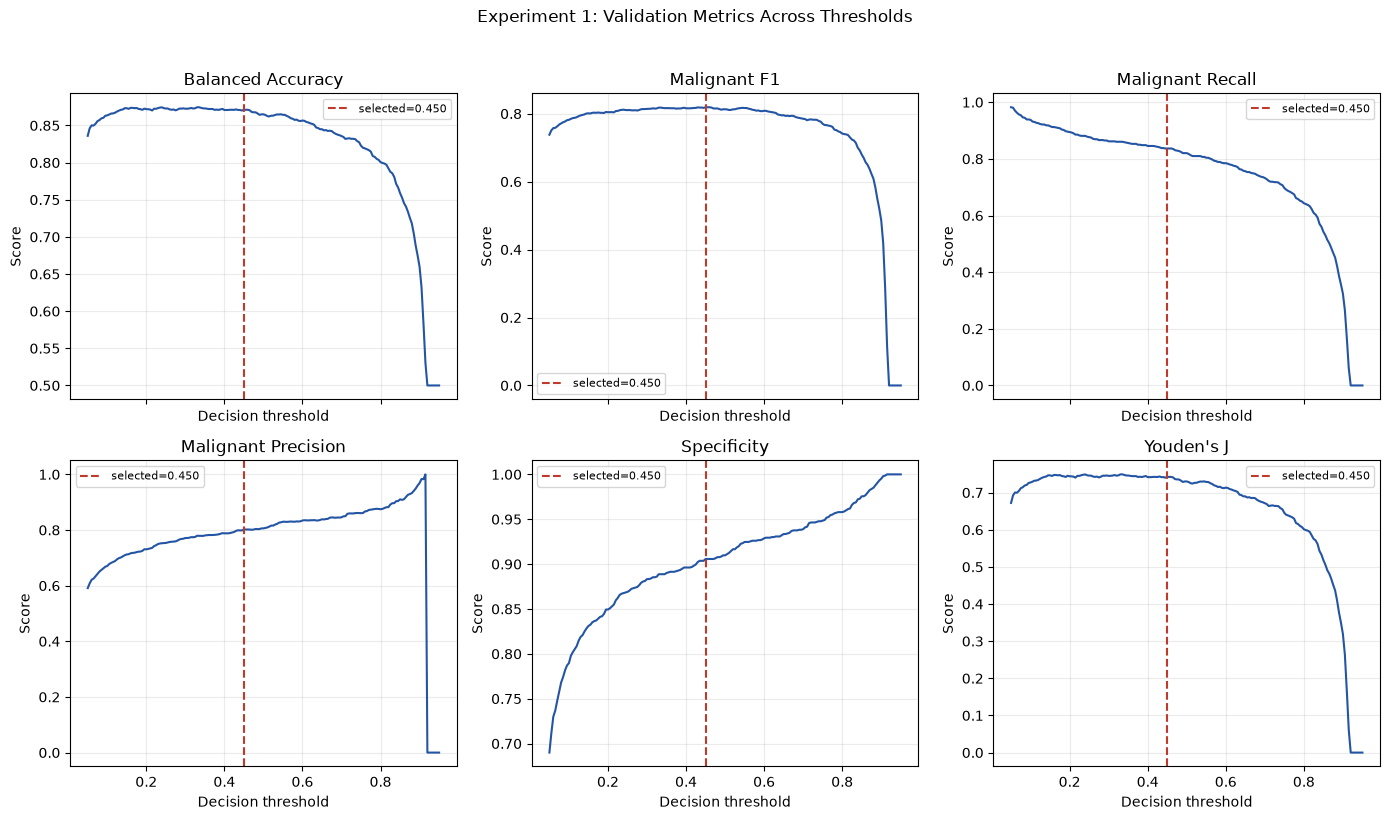

2026-08-22 11:38:44,897 | INFO | Selected Experiment 1 threshold: 0.450 (F1-optimal (current))


,candidate,threshold,balanced_accuracy,f1_score,recall,precision,specificity,youden_j,overall_balance_score
0,F1-optimal (current),0.45,0.871126,0.818909,0.836553,0.801994,0.905699,0.742252,0.846856
1,Balanced-Accuracy-optimal,0.33,0.874533,0.817797,0.860327,0.779273,0.888738,0.749065,0.844133
2,Youden's-J-optimal,0.33,0.874533,0.817797,0.860327,0.779273,0.888738,0.749065,0.844133
3,Constrained BA (Recall >= 0.8279),0.33,0.874533,0.817797,0.860327,0.779273,0.888738,0.749065,0.844133


In [16]:
CURRENT_BASELINE_RECALL = 0.8279
thresholds = np.round(np.arange(0.05, 0.9501, 0.005), 3)

def classification_metrics(labels, probabilities, threshold, include_auc=True):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    recall = recall_score(labels, predictions, zero_division=0)
    precision = precision_score(labels, predictions, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else float('nan')
    output = {
        'threshold': float(threshold),
        'accuracy': accuracy_score(labels, predictions),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'f1_score': f1_score(labels, predictions, zero_division=0),
        'recall': recall,
        'precision': precision,
        'specificity': specificity,
        'youden_j': recall + specificity - 1.0,
        'true_negatives': int(tn),
        'false_positives': int(fp),
        'false_negatives': int(fn),
        'true_positives': int(tp),
    }
    if include_auc:
        output.update({
            'roc_auc': roc_auc_score(labels, probabilities),
            'pr_auc': average_precision_score(labels, probabilities),
            'brier_score': brier_score_loss(labels, probabilities),
        })
    return output

threshold_rows = [
    classification_metrics(val_labels, baseline_val_probs, threshold, include_auc=False)
    for threshold in thresholds
]
threshold_sweep = pd.DataFrame(threshold_rows)
threshold_sweep.to_csv(OUTPUT_DIR / 'threshold_sweep_validation.csv', index=False)

def row_at_max(frame, column):
    return frame.loc[frame[column].idxmax()].copy()

candidates = {
    'F1-optimal (current)': row_at_max(threshold_sweep, 'f1_score'),
    'Balanced-Accuracy-optimal': row_at_max(threshold_sweep, 'balanced_accuracy'),
    "Youden's-J-optimal": row_at_max(threshold_sweep, 'youden_j'),
}
feasible = threshold_sweep[threshold_sweep['recall'] >= CURRENT_BASELINE_RECALL]
if feasible.empty:
    logger.warning('No threshold met Recall >= %.4f; constrained row uses the highest-recall grid point.', CURRENT_BASELINE_RECALL)
    constrained_row = threshold_sweep.sort_values(['recall', 'balanced_accuracy'], ascending=False).iloc[0].copy()
else:
    constrained_row = row_at_max(feasible, 'balanced_accuracy')
candidates['Constrained BA (Recall >= 0.8279)'] = constrained_row

candidate_rows = []
for candidate_name, row in candidates.items():
    record = row.to_dict()
    record['candidate'] = candidate_name
    record['overall_balance_score'] = np.mean([
        record['balanced_accuracy'], record['f1_score'], record['recall'],
        record['precision'], record['specificity'],
    ])
    candidate_rows.append(record)
threshold_candidates = pd.DataFrame(candidate_rows)
threshold_candidates = threshold_candidates[
    ['candidate', 'threshold', 'balanced_accuracy', 'f1_score', 'recall', 'precision',
     'specificity', 'youden_j', 'overall_balance_score']
]
threshold_candidates = threshold_candidates.sort_values(
    ['overall_balance_score', 'balanced_accuracy', 'f1_score'], ascending=False
).reset_index(drop=True)
selected_threshold = float(threshold_candidates.iloc[0]['threshold'])
selected_threshold_candidate = str(threshold_candidates.iloc[0]['candidate'])
threshold_candidates.to_csv(OUTPUT_DIR / 'threshold_candidates_validation.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
metrics_to_plot = [
    ('balanced_accuracy', 'Balanced Accuracy'),
    ('f1_score', 'Malignant F1'),
    ('recall', 'Malignant Recall'),
    ('precision', 'Malignant Precision'),
    ('specificity', 'Specificity'),
    ('youden_j', "Youden's J"),
]
for axis, (metric_name, title) in zip(axes.flat, metrics_to_plot):
    axis.plot(threshold_sweep['threshold'], threshold_sweep[metric_name], color='#2455a4')
    axis.axvline(selected_threshold, color='#c0392b', linestyle='--', label=f'selected={selected_threshold:.3f}')
    axis.set_title(title)
    axis.set_xlabel('Decision threshold')
    axis.set_ylabel('Score')
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.suptitle('Experiment 1: Validation Metrics Across Thresholds', y=1.02)
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / 'threshold_sweep_metrics.png', bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

logger.info('Selected Experiment 1 threshold: %.3f (%s)', selected_threshold, selected_threshold_candidate)
threshold_candidates

## 8. Experiment 2 — One fine-tuning pace-fix retrain

This is the only retraining run in the notebook. It uses the same architecture, loss, augmentation,
TTA, calibration method, scheduler, batch size, epoch limit, and early-stopping rule as the
baseline. The only bundled changes are the specified pace fixes:

| Setting | Original | Pace-fix run |
|---|---:|---:|
| Frozen warmup | 2 epochs | 4 epochs |
| Backbone learning rate | 1e-4 | 5e-5 |
| Weight decay | 1e-4 | 5e-4 |

Optional label smoothing is intentionally not added, so the requested run changes only the three
mandatory pace-fix settings.

train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 11:42:56,767 | INFO | [pace-fix epoch 1/20] train_loss=0.1142 train_auc=0.8291 train_acc=0.7506 | val_loss=0.1021 val_auc=0.8730 val_acc=0.7727


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 11:45:00,623 | INFO | [pace-fix epoch 2/20] train_loss=0.1072 train_auc=0.8528 train_acc=0.7652 | val_loss=0.0988 val_auc=0.8795 val_acc=0.7941


... (50 outputs left out)

2026-08-22 12:31:37,955 | INFO | [pace-fix epoch 19/20] train_loss=0.0265 train_auc=0.9926 train_acc=0.9570 | val_loss=0.1310 val_auc=0.9385 val_acc=0.8635


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 12:34:24,803 | INFO | [pace-fix epoch 20/20] train_loss=0.0215 train_auc=0.9950 train_acc=0.9656 | val_loss=0.1431 val_auc=0.9396 val_acc=0.8766


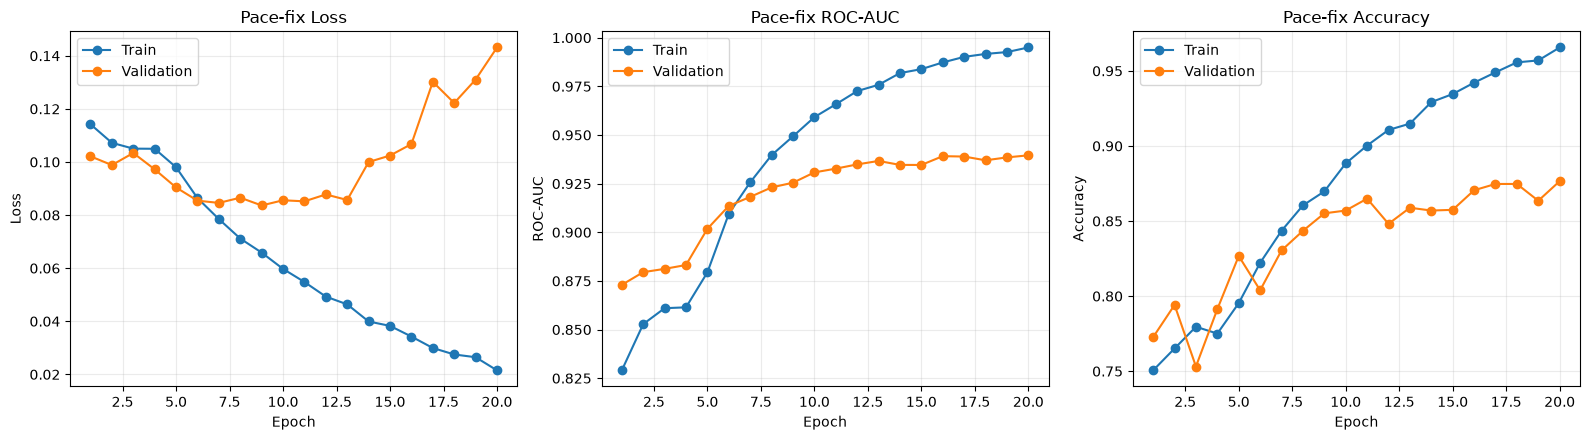

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

In [17]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, run_config=None):
    run_config = CONFIG if run_config is None else run_config
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0
    probabilities, labels = [], []
    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, batch_labels, _ in tqdm(loader, desc='train' if is_train else 'eval', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            batch_labels = batch_labels.to(DEVICE, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=run_config['use_amp']):
                logits = model(images)
                loss = criterion(logits, batch_labels)
            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), run_config['grad_clip_norm'])
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(batch_labels.detach().cpu().numpy())
    probabilities = np.concatenate(probabilities)
    labels = np.concatenate(labels).astype(int)
    loss_value = total_loss / len(loader.dataset)
    auc_value = roc_auc_score(labels, probabilities)
    acc_value = accuracy_score(labels, (probabilities >= 0.5).astype(int))
    return loss_value, auc_value, acc_value

pace_fix_config = dict(CONFIG)
pace_fix_config.update({
    'warmup_freeze_epochs': 4,
    'backbone_lr': 5e-5,
    'weight_decay': 5e-4,
    'label_smoothing': 0.0,
    'experiment': 'fine_tuning_pace_fix',
})

set_seed(RANDOM_STATE)
pace_fix_model = EfficientNetB3BinaryClassifier().to(DEVICE)
pace_fix_criterion = ClassBalancedFocalLoss(
    samples_per_class=[
        int((train_df['binary_label'] == 0).sum()),
        int((train_df['binary_label'] == 1).sum()),
    ],
    beta=pace_fix_config['cb_beta'],
    gamma=pace_fix_config['focal_gamma'],
    device=DEVICE,
)
pace_fix_optimizer = torch.optim.AdamW(
    pace_fix_model.head_parameters(),
    lr=pace_fix_config['head_lr'],
    weight_decay=pace_fix_config['weight_decay'],
)
pace_fix_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    pace_fix_optimizer, mode='max', factor=0.5, patience=2
)
pace_fix_scaler = GradScaler(enabled=pace_fix_config['use_amp'])

pace_fix_history = []
pace_fix_best_state = None
pace_fix_best_val_auc = -np.inf
epochs_without_improvement = 0
for epoch in range(1, pace_fix_config['epochs'] + 1):
    if epoch == pace_fix_config['warmup_freeze_epochs'] + 1:
        pace_fix_model.unfreeze_backbone()
        pace_fix_optimizer.add_param_group({
            'params': pace_fix_model.backbone_trainable_parameters(),
            'lr': pace_fix_config['backbone_lr'],
        })
        logger.info('Pace-fix unfreeze at epoch %d; backbone lr=%.1e', epoch, pace_fix_config['backbone_lr'])

    train_loss, train_auc, train_acc = run_epoch(
        pace_fix_model, train_loader, pace_fix_criterion,
        pace_fix_optimizer, pace_fix_scaler, pace_fix_config
    )
    val_loss, val_auc, val_acc = run_epoch(
        pace_fix_model, val_loader, pace_fix_criterion, None, None, pace_fix_config
    )
    pace_fix_scheduler.step(val_auc)
    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_auc': train_auc,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_auc': val_auc,
        'val_acc': val_acc,
    }
    pace_fix_history.append(row)
    logger.info(
        '[pace-fix epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | '
        'val_loss=%.4f val_auc=%.4f val_acc=%.4f',
        epoch, pace_fix_config['epochs'], train_loss, train_auc, train_acc,
        val_loss, val_auc, val_acc,
    )
    if val_auc > pace_fix_best_val_auc:
        pace_fix_best_val_auc = val_auc
        pace_fix_best_state = {
            'model_state': {key: value.detach().cpu().clone() for key, value in pace_fix_model.state_dict().items()},
            'epoch': epoch,
            'val_auc': val_auc,
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= pace_fix_config['early_stopping_patience']:
            logger.info('Pace-fix early stopping at epoch %d.', epoch)
            break

if pace_fix_best_state is None:
    raise RuntimeError('Pace-fix training did not produce a best checkpoint.')
pace_fix_model.load_state_dict(pace_fix_best_state['model_state'])
pace_fix_history_df = pd.DataFrame(pace_fix_history)
pace_fix_history_df.to_csv(OUTPUT_DIR / 'training_history_pace_fix.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, metric, ylabel in zip(
    axes,
    ['loss', 'auc', 'acc'],
    ['Loss', 'ROC-AUC', 'Accuracy'],
):
    axis.plot(pace_fix_history_df['epoch'], pace_fix_history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(pace_fix_history_df['epoch'], pace_fix_history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set_xlabel('Epoch')
    axis.set_ylabel(ylabel)
    axis.set_title(f'Pace-fix {ylabel}')
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / 'fine_tuning_pace_fix_curves.png', bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

if CONFIG['use_tta']:
    pace_fix_val_raw, pace_fix_val_labels, pace_fix_val_ids = collect_probs_tta(
        pace_fix_model, val_df, tta_transforms
    )
else:
    pace_fix_val_raw, pace_fix_val_labels, pace_fix_val_ids = collect_probs_single(
        pace_fix_model, val_loader
    )
if not np.array_equal(val_labels, pace_fix_val_labels) or val_ids != pace_fix_val_ids:
    raise RuntimeError('Validation ordering mismatch between baseline and pace-fix inference.')
pace_fix_calibrator = fit_platt_calibrator(pace_fix_val_raw, val_labels)
pace_fix_val_probs = calibrated_probabilities(pace_fix_calibrator, pace_fix_val_raw)

## 9. Validation comparison and locked model decision

The three validation rows are the original baseline threshold, the baseline checkpoint with the
Experiment 1 threshold, and the pace-fix model using the Experiment 1 threshold. The pace-fix
threshold is **not** re-optimized: this preserves the requested comparison.

McNemar's exact two-sided test is reported for baseline versus pace-fix predictions. The practical
malignant-case check also records the net change in malignant true positives; an improvement is
treated as meaningful only when it improves Balanced Accuracy or malignant F1, does not clearly
break Precision or Specificity (drop greater than 0.02), and is supported by either McNemar's test
at p < 0.05 or at least 15 additional malignant true positives on validation.

In [18]:
baseline_validation_metrics = classification_metrics(
    val_labels, baseline_val_probs, baseline_threshold, include_auc=True
)
threshold_only_validation_metrics = classification_metrics(
    val_labels, baseline_val_probs, selected_threshold, include_auc=True
)
pace_fix_validation_metrics = classification_metrics(
    val_labels, pace_fix_val_probs, selected_threshold, include_auc=True
)

validation_comparison = pd.DataFrame([
    {'version': 'Baseline', **baseline_validation_metrics},
    {'version': 'Threshold-only', **threshold_only_validation_metrics},
    {'version': 'Fine-tuning-fix (+ threshold)', **pace_fix_validation_metrics},
])
validation_comparison = validation_comparison[
    ['version', 'threshold', 'balanced_accuracy', 'f1_score', 'recall', 'precision',
     'specificity', 'roc_auc', 'pr_auc', 'brier_score']
]
validation_comparison.to_csv(OUTPUT_DIR / 'validation_comparison.csv', index=False)

def exact_mcnemar(labels, baseline_predictions, new_predictions):
    baseline_correct = baseline_predictions == labels
    new_correct = new_predictions == labels
    b = int(np.sum(baseline_correct & ~new_correct))
    c = int(np.sum(~baseline_correct & new_correct))
    discordant = b + c
    if discordant == 0:
        p_value = 1.0
    else:
        lower_tail = sum(math.comb(discordant, k) for k in range(0, min(b, c) + 1)) / (2 ** discordant)
        p_value = min(1.0, 2.0 * lower_tail)
    return {'b_baseline_only_correct': b, 'c_new_only_correct': c, 'discordant_pairs': discordant, 'p_value': p_value}

baseline_val_predictions = (baseline_val_probs >= baseline_threshold).astype(int)
pace_fix_val_predictions = (pace_fix_val_probs >= selected_threshold).astype(int)
mcnemar = exact_mcnemar(val_labels, baseline_val_predictions, pace_fix_val_predictions)
net_malignant_true_positive_gain = (
    pace_fix_validation_metrics['true_positives'] - baseline_validation_metrics['true_positives']
)
primary_improvement = (
    pace_fix_validation_metrics['balanced_accuracy'] > baseline_validation_metrics['balanced_accuracy']
    or pace_fix_validation_metrics['f1_score'] > baseline_validation_metrics['f1_score']
)
no_clear_precision_break = pace_fix_validation_metrics['precision'] >= baseline_validation_metrics['precision'] - 0.02
no_clear_specificity_break = pace_fix_validation_metrics['specificity'] >= baseline_validation_metrics['specificity'] - 0.02
statistically_or_practically_supported = (
    mcnemar['p_value'] < 0.05 or net_malignant_true_positive_gain >= 15
)
pace_fix_is_final = bool(
    primary_improvement
    and no_clear_precision_break
    and no_clear_specificity_break
    and statistically_or_practically_supported
)
selected_version = 'Fine-tuning-fix (+ threshold)' if pace_fix_is_final else 'Threshold-only'
selected_model = pace_fix_model if pace_fix_is_final else baseline_model
selected_calibrator = pace_fix_calibrator if pace_fix_is_final else baseline_calibrator
selected_val_raw = pace_fix_val_raw if pace_fix_is_final else baseline_val_raw
selected_val_probs = pace_fix_val_probs if pace_fix_is_final else baseline_val_probs
selected_val_ids = pace_fix_val_ids if pace_fix_is_final else val_ids
selected_model_state = pace_fix_best_state['model_state'] if pace_fix_is_final else original_checkpoint['model_state']

decision_summary = {
    'selected_version': selected_version,
    'selected_threshold': selected_threshold,
    'selected_threshold_candidate': selected_threshold_candidate,
    'mcnemar': mcnemar,
    'net_malignant_true_positive_gain': int(net_malignant_true_positive_gain),
    'pace_fix_is_final': pace_fix_is_final,
    'primary_improvement': primary_improvement,
    'no_clear_precision_break': no_clear_precision_break,
    'no_clear_specificity_break': no_clear_specificity_break,
    'statistically_or_practically_supported': statistically_or_practically_supported,
}
with open(OUTPUT_DIR / 'validation_decision.json', 'w') as handle:
    json.dump(decision_summary, handle, indent=2, default=str)

logger.info('Validation decision: %s', decision_summary)
validation_comparison.round(4)

2026-08-22 12:35:35,527 | INFO | Validation decision: {'selected_version': 'Threshold-only', 'selected_threshold': 0.45, 'selected_threshold_candidate': 'F1-optimal (current)', 'mcnemar': {'b_baseline_only_correct': 68, 'c_new_only_correct': 57, 'discordant_pairs': 125, 'p_value': 0.3711606948508096}, 'net_malignant_true_positive_gain': -14, 'pace_fix_is_final': False, 'primary_improvement': False, 'no_clear_precision_break': True, 'no_clear_specificity_break': np.True_, 'statistically_or_practically_supported': False}


,version,threshold,balanced_accuracy,f1_score,recall,precision,specificity,roc_auc,pr_auc,brier_score
0,Baseline,0.45,0.8711,0.8189,0.8366,0.8020,0.9057,0.9480,0.8910,0.0875
1,Threshold-only,0.45,0.8711,0.8189,0.8366,0.8020,0.9057,0.9480,0.8910,0.0875
2,Fine-tuning-fix (+ threshold),0.45,0.8617,0.8085,0.8158,0.8015,0.9077,0.9445,0.8872,0.0883


## 10. Save the selected checkpoint and threshold before touching test

The selected checkpoint is written to the original `checkpoints/best_model.pth` path. The Platt
calibrator coefficients and the locked threshold are stored alongside it so the final test result
is reproducible without fitting anything on test.

In [19]:
selected_config = dict(pace_fix_config if pace_fix_is_final else original_checkpoint.get('config', CONFIG))
selected_config['selected_version'] = selected_version
selected_checkpoint = {
    'model_state': selected_model_state,
    'config': selected_config,
    'best_epoch': pace_fix_best_state['epoch'] if pace_fix_is_final else original_checkpoint.get('best_epoch'),
    'best_val_auc': pace_fix_best_state['val_auc'] if pace_fix_is_final else original_checkpoint.get('best_val_auc'),
    'best_threshold': selected_threshold,
    'threshold_candidate': selected_threshold_candidate,
    'calibrator_coef': selected_calibrator.coef_.tolist(),
    'calibrator_intercept': selected_calibrator.intercept_.tolist(),
    'decision_summary': decision_summary,
}
torch.save(selected_checkpoint, CHECKPOINTS_DIR / 'best_model.pth')

# Keep the original output filename for the selected run's training history when available.
if pace_fix_is_final:
    pace_fix_history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
elif not (OUTPUT_DIR / 'training_history.csv').exists():
    pd.DataFrame().to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

## 11. Single final test-set evaluation

This is the first and only cell that reads the test images. It uses the selected model, the
validation-fitted Platt calibrator, and the threshold locked above. No threshold search, model
choice, calibration fitting, or other decision is performed on test.

In [20]:
if CONFIG['use_tta']:
    final_test_raw, final_test_labels, final_test_ids = collect_probs_tta(
        selected_model, test_df, tta_transforms
    )
else:
    final_test_raw, final_test_labels, final_test_ids = collect_probs_single(selected_model, test_loader)

final_test_probs = calibrated_probabilities(selected_calibrator, final_test_raw)
final_test_predictions = (final_test_probs >= selected_threshold).astype(int)
final_test_metrics = classification_metrics(
    final_test_labels, final_test_probs, selected_threshold, include_auc=True
)
final_test_metrics['threshold_used'] = selected_threshold
final_test_metrics['selected_version'] = selected_version
final_test_metrics['brier_score_before_calibration'] = brier_score_loss(final_test_labels, final_test_raw)
final_test_metrics['brier_score'] = brier_score_loss(final_test_labels, final_test_probs)

final_cm = confusion_matrix(final_test_labels, final_test_predictions, labels=[0, 1])
final_cm_df = pd.DataFrame(
    final_cm,
    index=['True Benign', 'True Malignant'],
    columns=['Predicted Benign', 'Predicted Malignant'],
)
final_cm_df.to_csv(OUTPUT_DIR / 'final_test_confusion_matrix.csv')
with open(OUTPUT_DIR / 'classification_report_f1_optimal.json', 'w') as handle:
    json.dump({
        'metrics': final_test_metrics,
        'classification_report': classification_report(
            final_test_labels, final_test_predictions,
            target_names=['Benign', 'Malignant'], output_dict=True
        ),
        'confusion_matrix': final_cm.tolist(),
    }, handle, indent=2, default=str)

predictions_df = pd.DataFrame({
    'image_id': final_test_ids,
    'true_label': final_test_labels.astype(int),
    'predicted_label': final_test_predictions.astype(int),
    'probability_benign': (1.0 - final_test_probs).astype(float),
    'probability_malignant': final_test_probs.astype(float),
})
required_prediction_columns = {
    'image_id', 'true_label', 'predicted_label',
    'probability_benign', 'probability_malignant',
}
if set(predictions_df.columns) != required_prediction_columns:
    raise RuntimeError('Final predictions do not have the required output contract.')
if predictions_df['image_id'].duplicated().any():
    raise RuntimeError('Final predictions contain duplicate image_id values.')
if set(predictions_df['image_id']) != set(test_df['image_id']):
    raise RuntimeError('Final predictions do not match test metadata image IDs exactly.')
predictions_df = test_df[['image_id']].merge(
    predictions_df, on='image_id', how='left', validate='one_to_one'
).sort_values('image_id').reset_index(drop=True)
predictions_df.to_csv(PREDICTIONS_DIR / 'predictions.csv', index=False)

# Save validation predictions at the original auxiliary path for ensemble compatibility.
val_predictions_df = pd.DataFrame({
    'image_id': selected_val_ids,
    'true_label': val_labels.astype(int),
    'predicted_label': (selected_val_probs >= selected_threshold).astype(int),
    'probability_benign': (1.0 - selected_val_probs).astype(float),
    'probability_malignant': selected_val_probs.astype(float),
}).sort_values('image_id').reset_index(drop=True)
val_predictions_df.to_csv(PREDICTIONS_DIR / 'val_predictions.csv', index=False)

with open(OUTPUT_DIR / 'metrics_summary.json', 'w') as handle:
    json.dump({
        'experiment_name': 'Binary_EfficientNetB3_Baseline_V2',
        'selected_version': selected_version,
        'selected_threshold': selected_threshold,
        'validation_comparison': validation_comparison.to_dict(orient='records'),
        'final_test_metrics': final_test_metrics,
        'confusion_matrix': final_cm.tolist(),
        'run_timestamp': RUN_TIMESTAMP,
    }, handle, indent=2, default=str)
with open(OUTPUT_DIR / 'run_config.json', 'w') as handle:
    json.dump({k: (str(v) if isinstance(v, Path) else v) for k, v in selected_config.items()}, handle, indent=2, default=str)

logger.info('Final selected version: %s', selected_version)
logger.info('Final test metrics: %s', json.dumps(final_test_metrics, indent=2, default=str))
print('Final test metrics:')
display(pd.DataFrame([final_test_metrics]).T.rename(columns={0: 'value'}))
print('Final test confusion matrix:')
display(final_cm_df)
print(
    f'Conclusion: Experiment 1 selected threshold {selected_threshold:.3f} '
    f'({selected_threshold_candidate}). Experiment 2 was '
    f"{'selected' if pace_fix_is_final else 'not selected'} as the final version."
    f' The validation decision used the exact McNemar p-value '
    f"({mcnemar['p_value']:.4g}) and a net malignant true-positive change of "
    f'{int(net_malignant_true_positive_gain)}. The test set was evaluated exactly once '
    'after the model and threshold were locked.'
)

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 12:37:19,820 | INFO | Final selected version: Threshold-only
2026-08-22 12:37:19,820 | INFO | Final test metrics: {
  "threshold": 0.45,
  "accuracy": 0.8872845831392641,
  "balanced_accuracy": 0.8707743336536389,
  "f1_score": 0.8215339233038348,
  "recall": 0.8264094955489614,
  "precision": 0.8167155425219942,
  "specificity": 0.9151391717583164,
  "youden_j": 0.7415486673072778,
  "true_negatives": 1348,
  "false_positives": 125,
  "false_negatives": 117,
  "true_positives": 557,
  "roc_auc": 0.9476335664110265,
  "pr_auc": 0.8983893376767874,
  "brier_score": 0.08359652060827372,
  "threshold_used": 0.45,
  "selected_version": "Threshold-only",
  "brier_score_before_calibration": 0.08465576171875
}


Final test metrics:


,value
threshold,0.45
accuracy,0.887285
balanced_accuracy,0.870774
f1_score,0.821534
recall,0.826409
precision,0.816716
specificity,0.915139
youden_j,0.741549
true_negatives,1348
false_positives,125


Final test confusion matrix:


,Predicted Benign,Predicted Malignant
True Benign,1348,125
True Malignant,117,557


Conclusion: Experiment 1 selected threshold 0.450 (F1-optimal (current)). Experiment 2 was not selected as the final version. The validation decision used the exact McNemar p-value (0.3712) and a net malignant true-positive change of -14. The test set was evaluated exactly once after the model and threshold were locked.
